/Users/elizabethmurphy/SRTI
['empirical_shedding_data.csv']


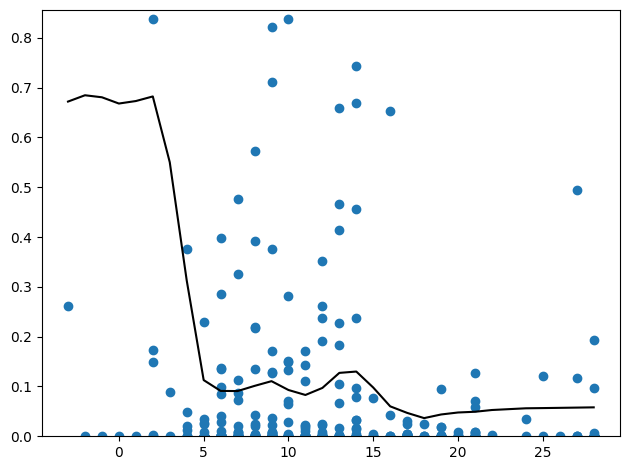

In [7]:
os.chdir('/Users/elizabethmurphy/SRTI')

print(os.getcwd())
print(os.listdir('data'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# using data from https://journals.asm.org/doi/10.1128/msphere.00132-23

import statsmodels.api as sm
lowess = sm.nonparametric.lowess
shed_data = pd.read_csv('data/empirical_shedding_data.csv')

shed_data['N_conc (gc/mg-dw)'] = shed_data['N_conc (gc/mg-dw)']/shed_data['PMMoV_conc (gc/mg-dw)']
# shed_data = shed_data.dropna(how='any')
curve =lowess(shed_data['N_conc (gc/mg-dw)'],shed_data['Day'],frac=0.25)
curve = np.unique(curve, axis=0)

from scipy import interpolate
kernel_length = curve.shape[0]
maxT = kernel_length-1
f = interpolate.interp1d(range(0,kernel_length), curve[:,1])


# plot raw data in log scaling
fig,ax = plt.subplots()
ax.scatter(shed_data['Day'],shed_data['N_conc (gc/mg-dw)'])
# ax.set_yscale('log')
fig.tight_layout()
fig.savefig('plots/shedding_raw_data_just_data.pdf')
plt.close()

# plot shedding curve, not including outliers
fig,ax = plt.subplots()
ax.scatter(shed_data['Day'],shed_data['N_conc (gc/mg-dw)'])
ax.plot(curve[:,0],curve[:,1],color='black')
ax.set_ylim([0,curve[:,1].max()*1.25])
fig.tight_layout()
# fig.savefig('plots/shedding_raw_data.pdf')
# plt.close()

['plots.ipynb', '.DS_Store', 'plot_shedding.py', 'README.md', '.git', 'script.py', 'data', 'plots']
